# 🖼️ Jev 1.14 — décisions sur images (Google Colab)

**Meetup IA — démo OpenRouter**

Jev (TypeSafe) n'est **pas un LLM** : il ne génère pas de texte. On lui envoie une `state`
(texte + image) et des `questions` **typées** ; il répond par des décisions structurées
exploitables directement par du code.

| | |
|---|---|
| Modèle | `typesafe/jev-1.14` |
| Entrée | texte + **images** (PNG/JPEG) |
| Primitives | `choice` · `noul` · `score` · **`box`** |
| Contexte | 262 144 tokens |
| Prix | **$0.042 / M input**, sortie **gratuite** |
| Endpoint | `POST https://openrouter.ai/api/alpha/decisions` |

> ⚠️ Image + `box` sont des features **early / danger zone** : parfaites pour explorer, pas encore pour la prod.
> Docs : <https://openrouter.ai/docs/guides/community/multimodal-decisions>

In [1]:
!pip -q install requests pillow

## 1. Clé API

Ajoute un secret Colab nommé **`OPENROUTER_API_KEY`** (icône 🔑 à gauche).
Ne colle jamais la clé en clair dans une cellule.

In [2]:
import base64, io, json, os
import requests
from PIL import Image, ImageDraw, ImageOps
from IPython.display import display

ENDPOINT = "https://openrouter.ai/api/alpha/decisions"
MODEL = "typesafe/jev-1.14"

try:
    from google.colab import userdata  # type: ignore
    API_KEY = userdata.get("OPENROUTER_API_KEY")
except Exception:
    API_KEY = os.environ.get("OPENROUTER_API_KEY")

assert API_KEY, "Renseigne le secret OPENROUTER_API_KEY."
print("Clé OpenRouter: OK")

Clé OpenRouter: OK


## 2. Préparer l'image

Jev impose : **PNG/JPEG**, chaque côté entre **256 et 1568 px**, et **78 400 à 2 458 624**
pixels au total. `prepare_image()` normalise toute image (rotation EXIF, redimensionnement, réencodage).

In [16]:
JPEG_MIME = "image/jpeg"

def prepare_image(path, out_path="/tmp/jev_input.jpg"):
    """Redimensionne + réencode une image aux limites Jev et renvoie le chemin."""
    src = Image.open(io.BytesIO(path)) if isinstance(path, (bytes, bytearray)) else Image.open(path)
    img = ImageOps.exif_transpose(src).convert("RGB")   # EXIF non appliqué côté Jev

    w, h = img.size
    scale = min(1.0, 1568 / max(w, h))          # jamais > 1568 px par côté
    if min(w, h) * scale < 300:                 # jamais < 300 px par côté
        scale = 300 / min(w, h)
    new_size = (round(w * scale), round(h * scale))
    if new_size != (w, h):
        img = img.resize(new_size, Image.LANCZOS)

    img.save(out_path, "JPEG", quality=90)
    print(f"Image préparée : {new_size[0]}x{new_size[1]} px -> {out_path}")
    return out_path

def to_data_url(path):
    with open(path, "rb") as fh:
        b64 = base64.b64encode(fh.read()).decode("ascii")
    return f"data:{JPEG_MIME};base64,{b64}"

## 3. Requête Decisions + lecture des réponses

`state` = liste de chaînes + un part image `{"type":"image_url", "image_url":{"url":"data:..."}}`.

In [17]:
def ask_jev(image_path, questions, preamble="Image analysée :"):
    payload = {
        "model": MODEL,
        "state": [
            preamble,
            {"type": "image_url", "image_url": {"url": to_data_url(image_path)}},
        ],
        "questions": questions,
    }
    resp = requests.post(
        ENDPOINT,
        headers={"Authorization": f"Bearer {API_KEY}", "Content-Type": "application/json"},
        json=payload,
        timeout=60,
    )
    if not resp.ok:
        raise RuntimeError(f"HTTP {resp.status_code}: {resp.text[:400]}")
    return resp.json()

def show_answers(raw):
    for name, ans in raw.get("answers", {}).items():
        kind = ans.get("type")
        if kind == "choice":
            print(f"  {name:14s} choice = {ans['choice']:12s} conf={ans.get('confidence', 0):.2f}")
        elif kind == "noul":
            print(f"  {name:14s} noul   = {ans.get('noul', 0):.3f}  (probabilité de oui)")
        elif kind == "score":
            print(f"  {name:14s} score  = {ans.get('score', 0):.2f}  conf={ans.get('confidence', 0):.2f}")
            if ans.get("legend"):
                print(f"                 legend = {ans['legend']}")
        elif kind == "box":
            b = ans.get("box", {})
            print(f"  {name:14s} box    = top={b.get('top'):.2f} bottom={b.get('bottom'):.2f} "
                  f"left={b.get('left'):.2f} right={b.get('right'):.2f} conf={ans.get('confidence', 0):.2f}")
        else:
            print(f"  {name:14s} {json.dumps(ans, ensure_ascii=False)}")
    u = raw.get("usage", {})
    print(f"\n  tokens in={u.get('input_tokens')} · coût=${u.get('cost', 0):.6f} · {raw.get('provider')}")

def draw_box(image_path, box, out_path=None):
    """Dessine la boîte renvoyée (fractions 0-1) sur l'image."""
    img = Image.open(image_path).convert("RGB")
    w, h = img.size
    xy = (box["left"] * w, box["top"] * h, box["right"] * w, box["bottom"] * h)
    ImageDraw.Draw(img).rectangle(xy, outline=(220, 40, 40), width=max(3, w // 150))
    if out_path:
        img.save(out_path)
    return img

## 4. ⚙️ Réglages : ta cible et ton image

**`CIBLE_BOX`** = la **description** de ce que tu veux localiser.
Le `box` suit cette description à la lettre — change-la pour viser autre chose
(ex. `"le chien dans l'image analysée"`, `"la tête du chien dans l'image analysée"`).
⚠️ Écris une **description** (« la tête du chien »), pas une consigne (« encadre la tête »),
et **nomme l'image**.

In [18]:
CIBLE_BOX = "la tête du chien (visage et oreilles) dans l'image analysée"
PREAMBULE = "Image analysée :"

# --- Ton image : upload Colab (ou mets un chemin direct) ----------------------
IMAGE_PATH = None
try:
    from google.colab import files
    uploaded = files.upload()
    IMAGE_PATH = list(uploaded)[0]
except Exception:
    IMAGE_PATH = None

if not IMAGE_PATH:  # image de secours : carré rouge sur fond clair
    _img = Image.new("RGB", (640, 480), (245, 245, 240))
    ImageDraw.Draw(_img).rectangle((300, 240, 500, 400), fill=(200, 30, 30))
    _img.save("/tmp/demo.png")
    IMAGE_PATH = "/tmp/demo.png"
    print("Aucun fichier chargé → image de test utilisée.")
print("Image :", IMAGE_PATH)

Saving cute_dog.jpg to cute_dog (2).jpg
Image : cute_dog (2).jpg


## 5. Lancer la démo

Image préparée : 612x408 px -> /tmp/jev_input.jpg
Calcul de la boîte stabilisée en cours (3 essais)...

Boîte finale stabilisée :
  box = top=0.18 bottom=0.48 left=0.31 right=0.63 (confiance moyenne: 0.63)


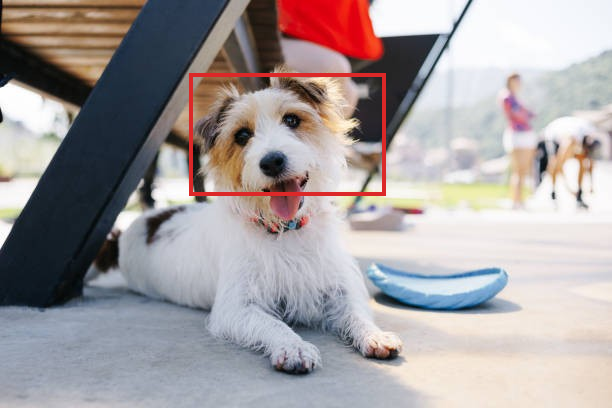

In [19]:
prepared = prepare_image(IMAGE_PATH)

# Nous utilisons la formulation la plus descriptive pour cibler tout le visage
cible_instructions = "le visage complet du chien (comprenant les yeux, le museau, la truffe et les oreilles) dans l'image analysée"

# Pour éviter les boîtes décalées (off-center), nous utilisons la fonction avg_box pour stabiliser le résultat
print("Calcul de la boîte stabilisée en cours (3 essais)...")
_box, _conf = avg_box(prepared, cible_instructions, n=3)

print(f"\nBoîte finale stabilisée :\n  box = top={_box['top']:.2f} bottom={_box['bottom']:.2f} left={_box['left']:.2f} right={_box['right']:.2f} (confiance moyenne: {_conf:.2f})")

display(draw_box(prepared, _box))

## 6. 🔎 Améliorer la box

La `box` est la feature la plus « early ». Mesures réelles sur une photo de chien (612×408) :

| Formulation de `CIBLE_BOX` | Confiance |
|---|---|
| `la tête du chien` | ~0.57 |
| `la tête du chien (visage et oreilles)` | **~0.75** |
| description longue avec le décor | ~0.62 |

**Le levier n°1 : décrire la cible par ses éléments visibles** (visage, oreilles, yeux…),
pas par son nom seul. Et **toujours nommer l'image** (« … dans l'image analysée »).

Autres leviers :
- **Cible trop petite** → recadrer : localiser d'abord la zone (`box`), recadrer avec ~10 % de marge,
  agrandir, puis relancer `box` sur le recadrage (les coordonnées reviennent en fractions du recadrage
  → à remapper).
- **Stabiliser** : lancer N fois et prendre la **médiane** des 4 bords (`avg_box`).
- **Confiance < ~0.6** → résultat peu fiable : reformuler la cible, ou considérer qu'elle est absente.
- `box` renvoie **toujours** une boîte → ajouter une question `noul` pour vérifier la présence réelle.

In [7]:
def avg_box(image_path, instructions, n=3):
    """Lance n fois la question box et renvoie la médiane des 4 bords + confiance moyenne."""
    edges = {"top": [], "bottom": [], "left": [], "right": []}
    confs = []
    for _ in range(n):
        raw = ask_jev(image_path, {"cible": {"type": "box", "instructions": instructions}})
        a = raw["answers"]["cible"]
        for k in edges:
            edges[k].append(a["box"][k])
        confs.append(a.get("confidence", 0))
    box = {k: sorted(v)[len(v) // 2] for k, v in edges.items()}
    return box, sum(confs) / len(confs)

# Effet de la formulation (même image) :
for phrase in [
    "la tête du chien dans l'image analysée",
    "la tête du chien (visage et oreilles) dans l'image analysée",
]:
    _b, _c = avg_box(prepared, phrase, n=3)
    print(f"conf={_c:.2f}  box={ {k: round(v, 3) for k, v in _b.items()} }  <- {phrase!r}")

conf=0.58  box={'top': 0.16, 'bottom': 0.46, 'left': 0.31, 'right': 0.63}  <- "la tête du chien dans l'image analysée"
conf=0.68  box={'top': 0.16, 'bottom': 0.45, 'left': 0.31, 'right': 0.62}  <- "la tête du chien (visage et oreilles) dans l'image analysée"


---
### Idées à explorer
- **Modération / tri** d'images (`choice`) : catégoriser un flux d'uploads.
- **Contrôle qualité** (`noul` + `score`) : une photo est-elle nette, bien cadrée ?
- **Localisation** (`box`) : recadrer un produit, un visage, un défaut…
- **Box + Noul ensemble** : `box` renvoie *toujours* une boîte — ajoute une question `noul`
  pour vérifier que la cible est réellement présente.

Coût observé : **~$0.00006 par appel**. 🎯